#### Done on 25.11.2026 using qiskit 2.0.3

In [1]:
! python -c 'import qiskit; print(qiskit.__version__);'

2.6.2


In [2]:
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter
from qiskit.quantum_info import SparsePauliOp

from qiskit_aer import Aer
from qiskit.visualization import array_to_latex
import qiskit.quantum_info as qi
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

In [3]:
from qiskit.synthesis import SuzukiTrotter
from qiskit_algorithms import TrotterQRTE
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import TimeEvolutionProblem

In [4]:
def get_hamiltonian(L, J, h, alpha=0):

    # List of Hamiltonian terms as 3-tuples containing
    # (1) the Pauli string,
    # (2) the qubit indices corresponding to the Pauli string,
    # (3) the coefficient.
    ZZ_tuples = [("ZZ", [i, i + 1], -J) for i in range(0, L - 1)]
    Z_tuples = [("Z", [i], -h * np.sin(alpha)) for i in range(0, L)]
    X_tuples = [("X", [i], -h * np.cos(alpha)) for i in range(0, L)]

    # We create the Hamiltonian as a SparsePauliOp, via the method
    # `from_sparse_list`, and multiply by the interaction term.
    hamiltonian = SparsePauliOp.from_sparse_list([*ZZ_tuples, *Z_tuples, *X_tuples], num_qubits=L)
    return hamiltonian.simplify()

In [5]:
L = 6
H = get_hamiltonian(L=L, J=0.2, h=1.2, alpha=np.pi / 8)
initial_state = qi.Statevector.from_label("001100")
final_time = 30
num_timesteps = 60

In [6]:
magnetization_op = SparsePauliOp.from_sparse_list(
    [("Z", [i], 1.0) for i in range(0, L)], num_qubits=L
)
correlation_op = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1.0) for i in range(0, L - 1)], num_qubits=L
) / (L - 1)

In [7]:
trotter = TrotterQRTE(
    SuzukiTrotter(order=4), num_timesteps=num_timesteps, estimator=StatevectorEstimator()
)
problem = TimeEvolutionProblem(
    H,
    initial_state=initial_state,
    time=final_time,
    aux_operators=[H, magnetization_op, correlation_op],
)
result = trotter.evolve(problem)
observables = np.array(np.array(result.observables)[:, :, 0], dtype=np.float64)

/home/aegis/Documents/Academe/1_IMAPP/1st Sem - UCA/QM_Computing/qiskit/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/aegis/Documents/Academe/1_IMAPP/1st Sem - UCA/QM_Computing/qiskit/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Text(0.5, 0.98, 'Observable evolution')

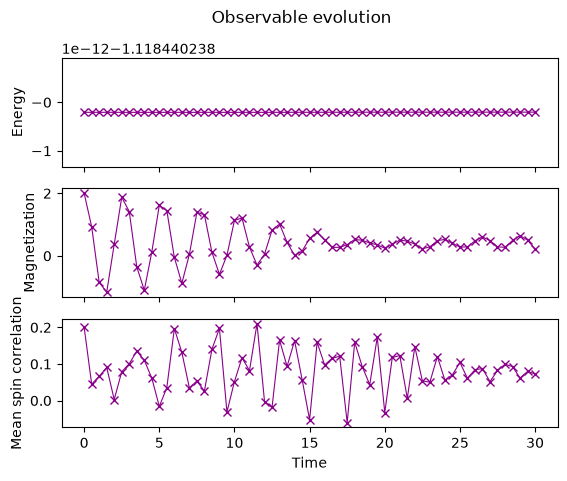

In [8]:
fig, axes = plt.subplots(3, sharex=True)
times = np.linspace(0, final_time, num_timesteps + 1)  # includes initial state
axes[0].plot(
    times, observables[:, 0], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[1].plot(
    times, observables[:, 1], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[2].plot(
    times, observables[:, 2], label="First order", marker="x", c="darkmagenta", ls="-", lw=0.8
)
axes[0].set_ylabel("Energy")
axes[1].set_ylabel("Magnetization")
axes[2].set_ylabel("Mean spin correlation")
axes[2].set_xlabel("Time")
fig.suptitle("Observable evolution")

#### exact calculation

In [9]:
op = H.to_matrix()
exact_times = np.linspace(0, final_time, 101)
exact_evolution = [initial_state.evolve(sp.linalg.expm(-1j * time * op)) for time in exact_times]

In [10]:
exact_energy = np.real([sv.expectation_value(H) for sv in exact_evolution])
exact_magnetization = np.real([sv.expectation_value(magnetization_op) for sv in exact_evolution])
exact_correlation = np.real([sv.expectation_value(correlation_op) for sv in exact_evolution])

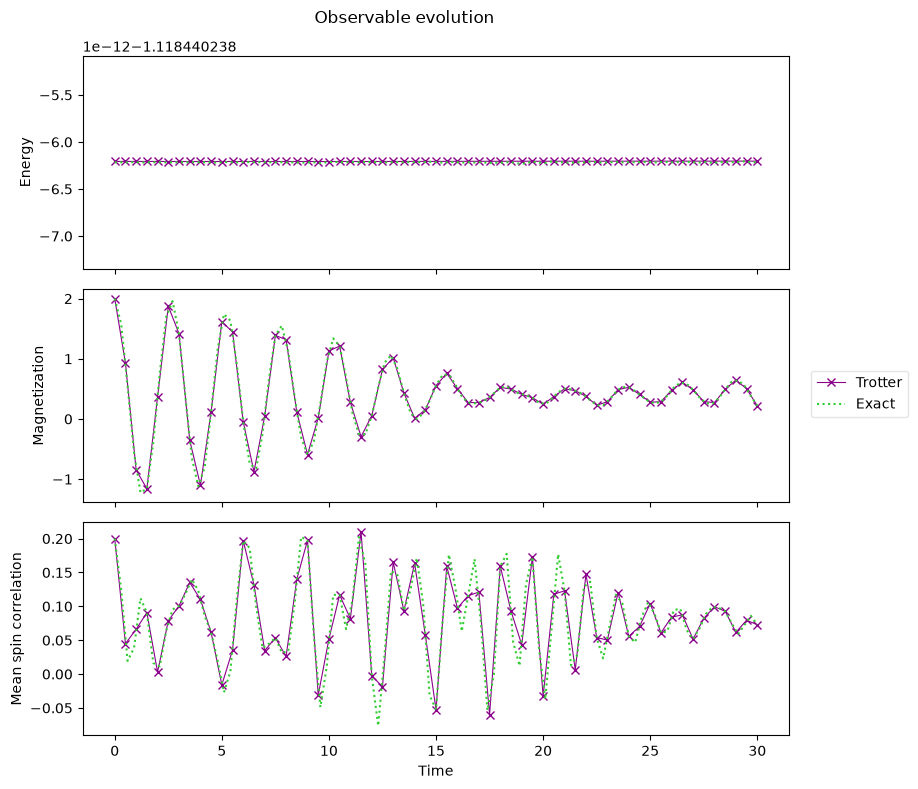

In [11]:
fig, axes = plt.subplots(3, sharex=True, figsize=(8,8))
times = np.linspace(0, final_time, num_timesteps + 1) # includes initial state
axes[0].plot(times, observables[:, 0], label='Trotter', marker='x', c='darkmagenta', ls='-', lw=.8)
axes[1].plot(times, observables[:, 1], label='Trotter', marker='x', c='darkmagenta', ls='-', lw=.8)
axes[2].plot(times, observables[:, 2], label='Trotter', marker='x', c='darkmagenta', ls='-', lw=.8)
axes[0].set_ylabel("Energy")
axes[1].set_ylabel("Magnetization")
axes[2].set_ylabel("Mean spin correlation")
axes[2].set_xlabel("Time")
fig.suptitle("Observable evolution")

axes[0].plot(exact_times, exact_energy, c='limegreen', ls=':', label='Exact')
axes[1].plot(exact_times, exact_magnetization, c='limegreen', ls=':', label='Exact')
axes[2].plot(exact_times, exact_correlation, c='limegreen', ls=':', label='Exact')
# Select the labels of only the first axis
legend = fig.legend(*axes[0].get_legend_handles_labels(), bbox_to_anchor=(1., .5), loc='center left', framealpha=.5)
fig.tight_layout()